In [1]:
suppressPackageStartupMessages({
library(Seurat)
library(SeuratWrappers)
library(dplyr)
library(dittoSeq)
library(patchwork)
})

theme_set(theme_classic(16))

# Set working directory for saving and accessing files
setwd("/data/pam/team333/skb/scratch/SNIP_paper/04_analysis/")
set.seed(123)

In [3]:
# Load QC-filtered and merged Seurat objects
Hcon_obj <- readRDS(file = "seurat_obj/Hcon_merged_2kHVG.rds")
Tmur_obj <- readRDS(file = "seurat_obj/Tmur_merged_2kHVG.rds")

In [ ]:
# Unintegrated clustering for Haemonchus contortus samples
Hcon_obj <- RunPCA(Hcon_obj) %>%
    FindNeighbors(dims = 1:30, reduction = "pca") %>% 
    FindClusters(resolution = 0.8, cluster.name = "unintegrated_clusters") %>%
    RunUMAP(dims=1:30, reduction = "pca", reduction.name = "umap.unintegrated")

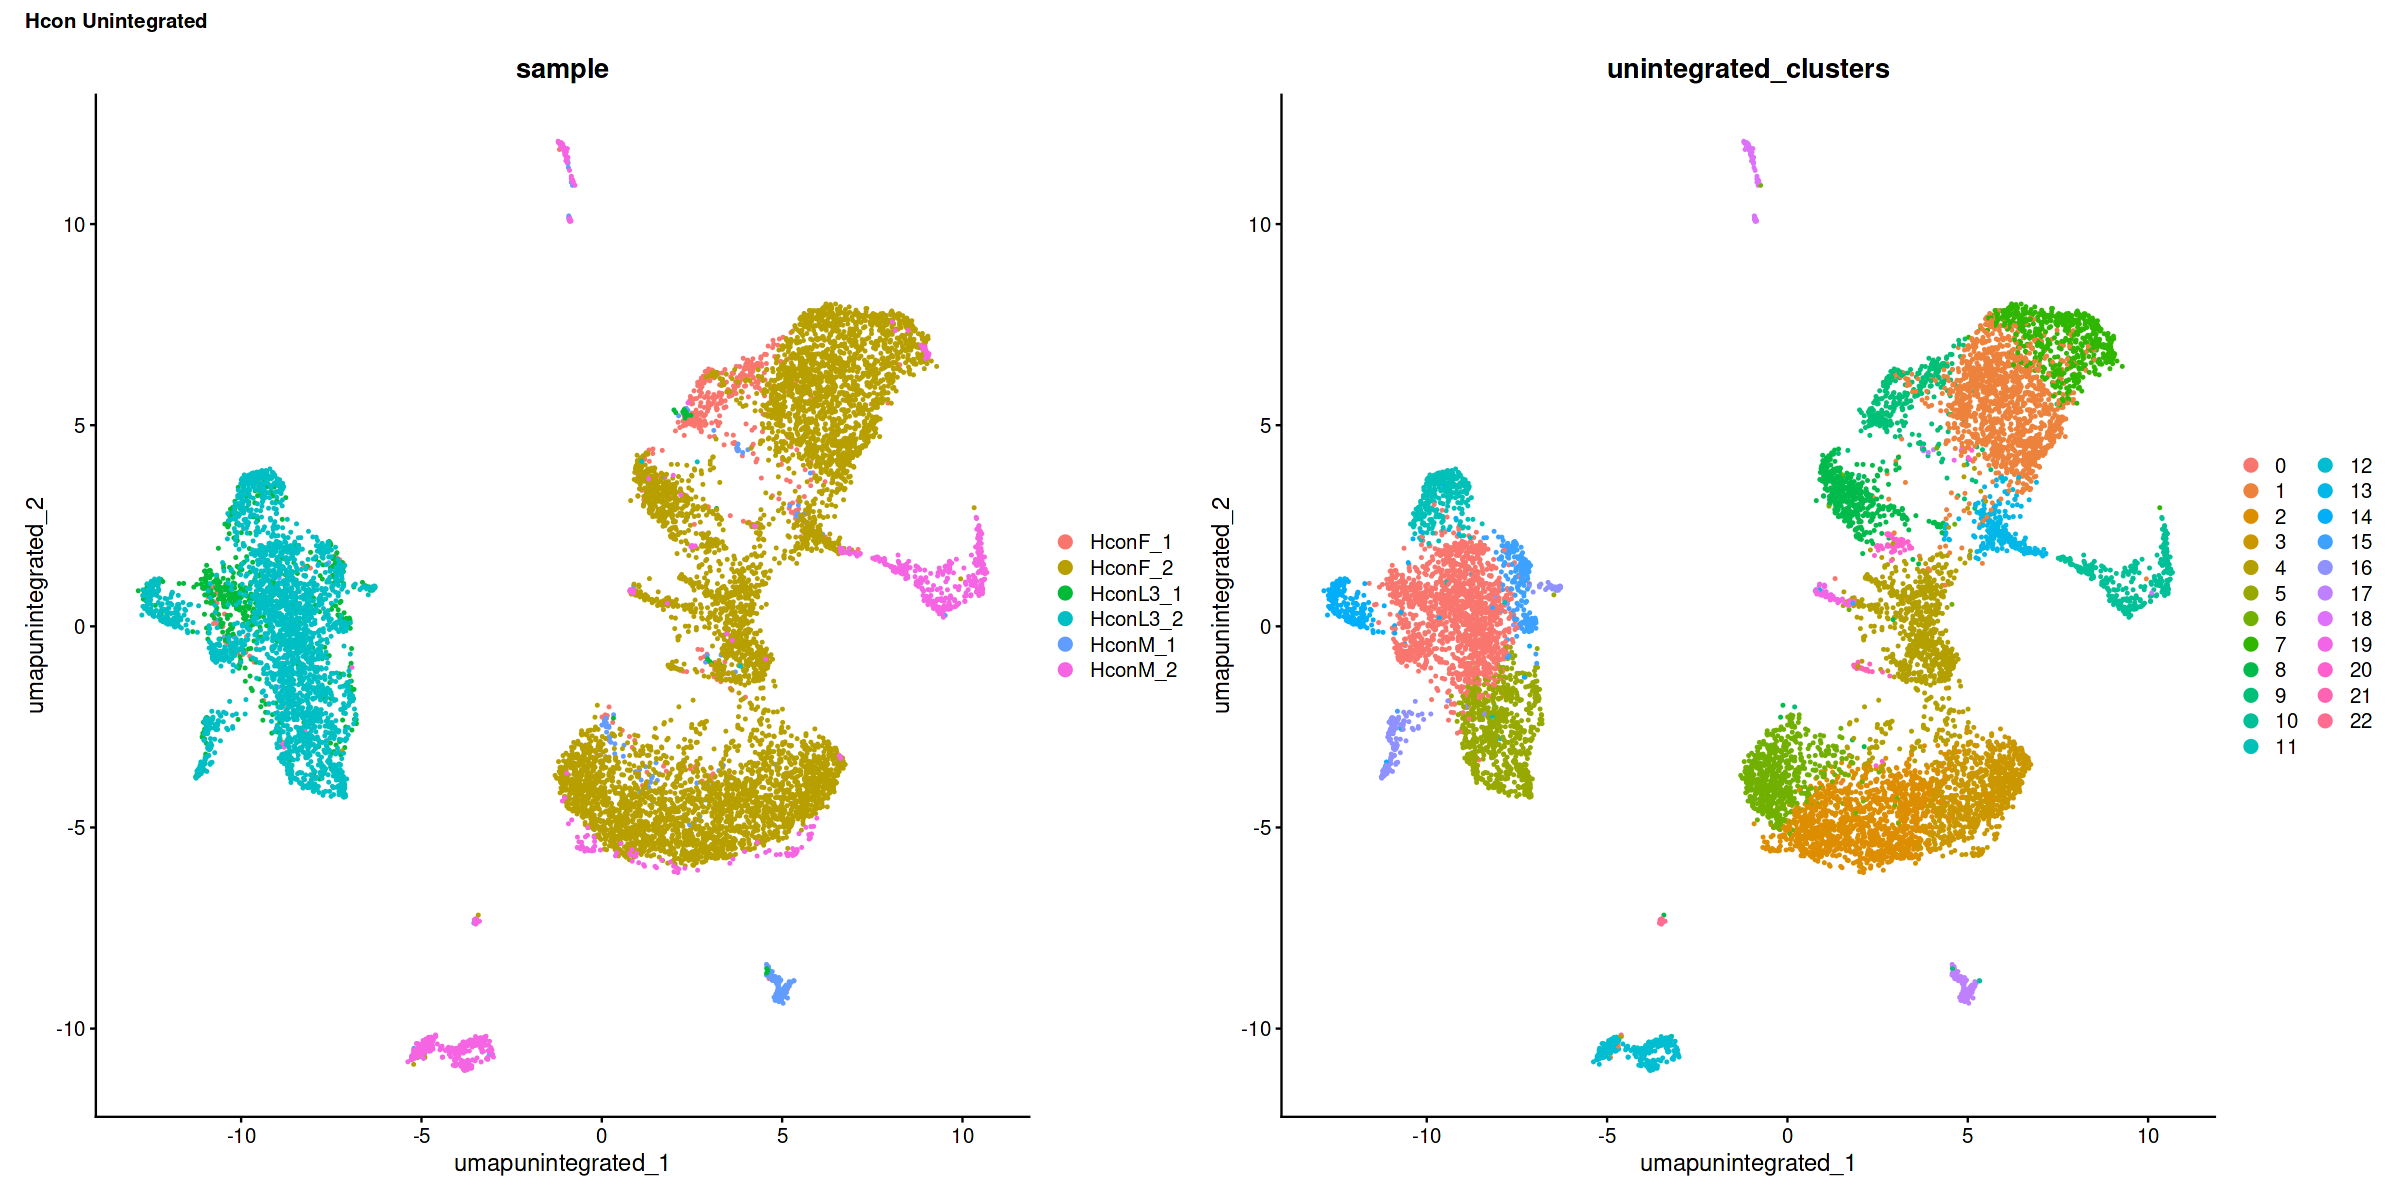

In [7]:
options(repr.plot.width=20, repr.plot.height=10)
DimPlot(Hcon_obj, reduction = "umap.unintegrated", raster = FALSE, group.by = c("sample", "unintegrated_clusters")) + plot_annotation(title = 'Hcon Unintegrated', theme = theme(plot.title = element_text(size = 12, face = "bold")))
ggsave(file = "Hcon_unintegrated_UMAP.png", width = 10, height = 5, dpi = 600, units = "in")

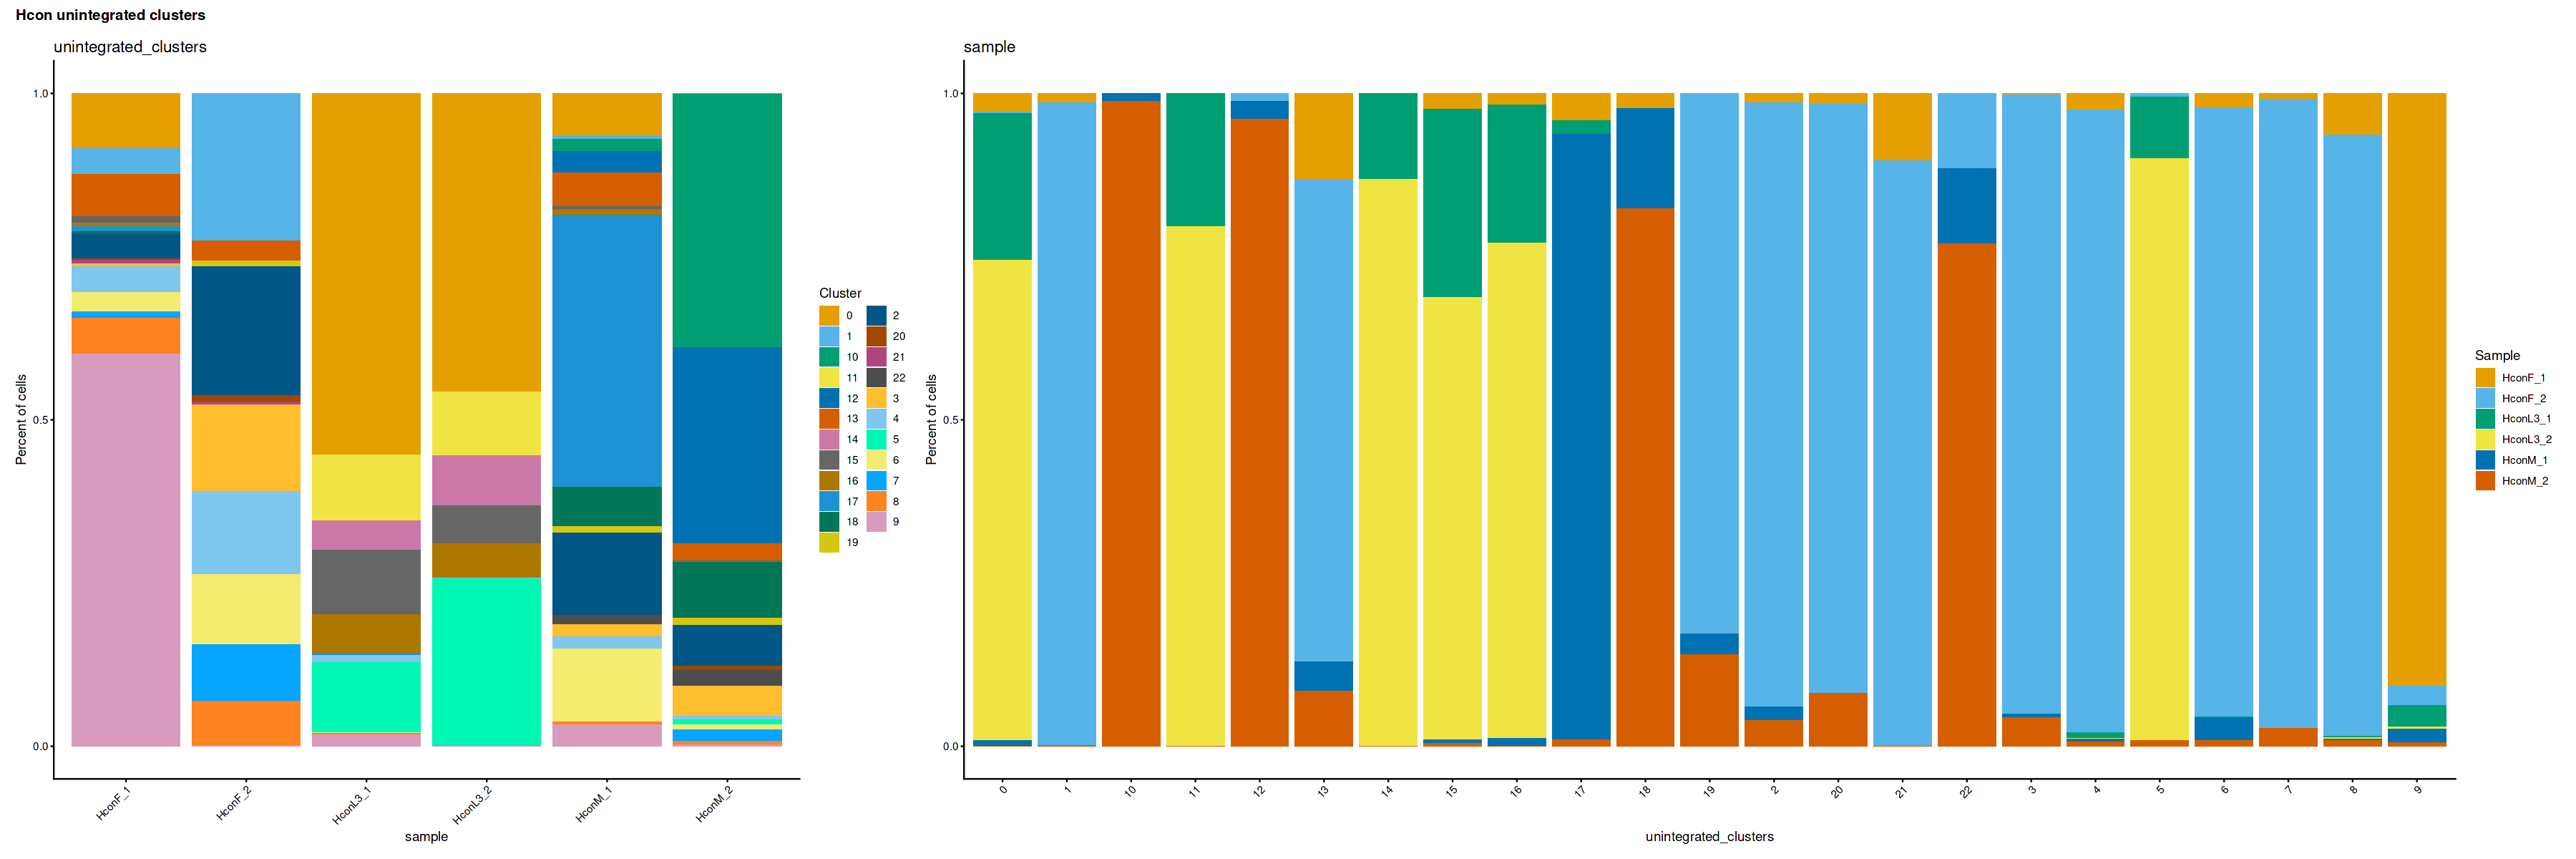

In [8]:
options(repr.plot.width=30, repr.plot.height=10)
p1 <- dittoBarPlot(Hcon_obj, var = "unintegrated_clusters", group.by = "sample", scale = "percent", legend.title = "Cluster") + plot_annotation(title = 'Hcon unintegrated clusters', theme = theme(plot.title = element_text(size = 12, face = "bold")))
p2 <- dittoBarPlot(Hcon_obj, var = "sample", group.by = "unintegrated_clusters", scale = "percent", legend.title = "Sample")
p1 + p2 + plot_layout(widths = c(10, 20))
ggsave(file = "Hcon_unintegrated_cluster_percent.png", width = 15, height = 5, dpi = 600, units = "in")

In [ ]:
# Unintegrated clustering for Trichuris muris samples
Tmur_obj <- RunPCA(Tmur_obj) %>%
    FindNeighbors(dims = 1:30, reduction = "pca") %>% 
    FindClusters(resolution = 0.8, cluster.name = "unintegrated_clusters") %>%
    RunUMAP(dims=1:30, reduction = "pca", reduction.name = "umap.unintegrated")

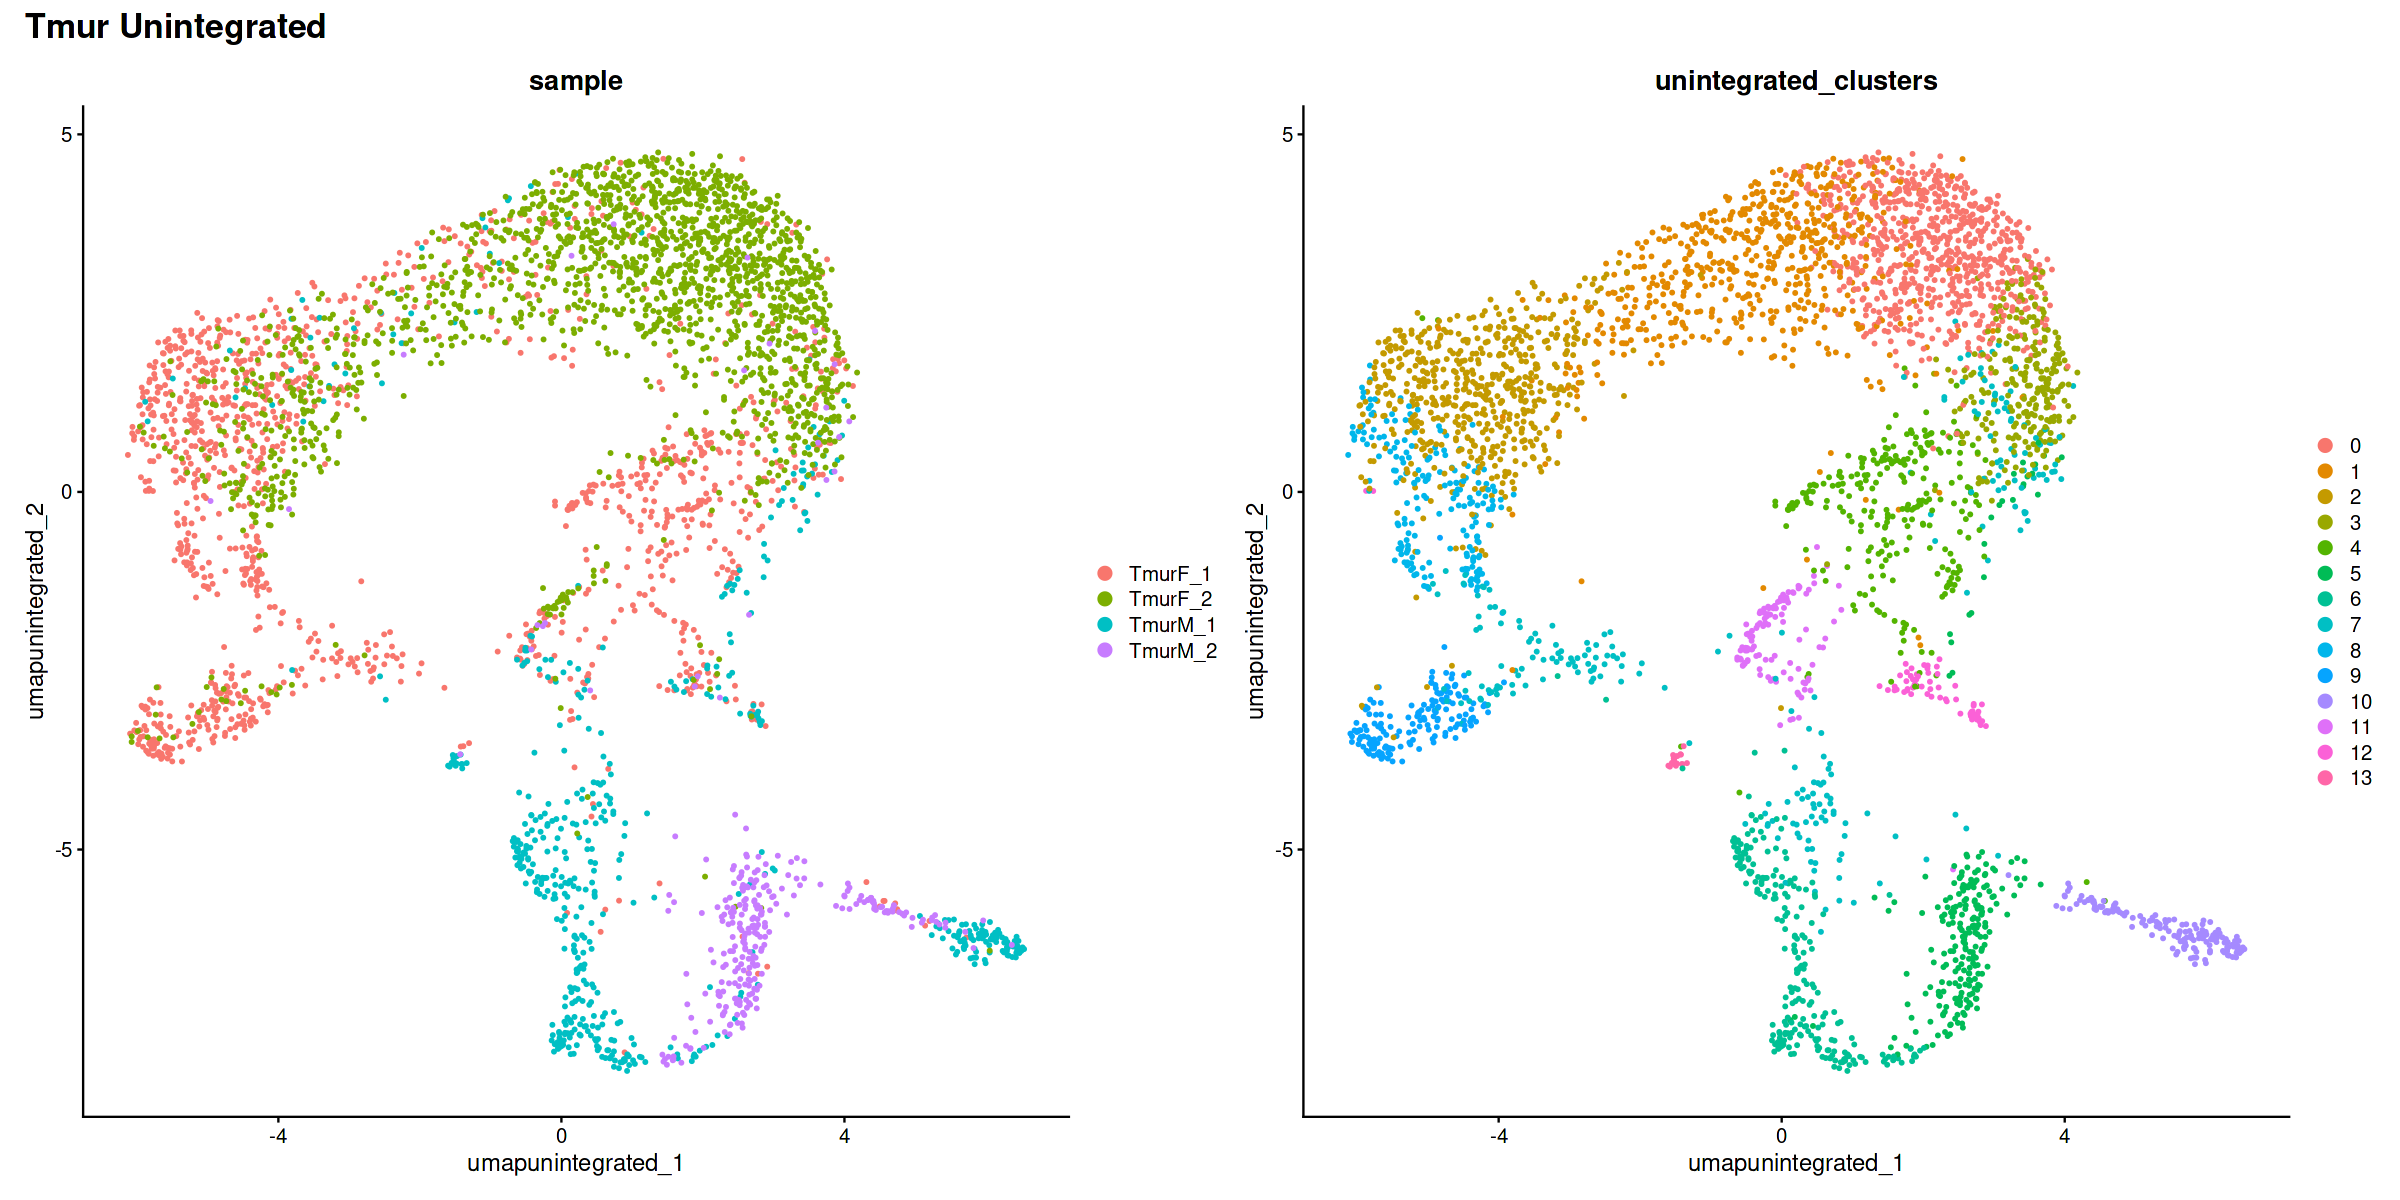

In [11]:
options(repr.plot.width=20, repr.plot.height=10)
DimPlot(Tmur_obj, reduction = "umap.unintegrated", raster = FALSE, group.by = c("sample", "unintegrated_clusters")) + plot_annotation(title = 'Tmur Unintegrated', theme = theme(plot.title = element_text(size = 20, face = "bold")))
ggsave(file = "Tmur_unintegrated_UMAP.png", width = 10, height = 5, dpi = 600, units = "in")

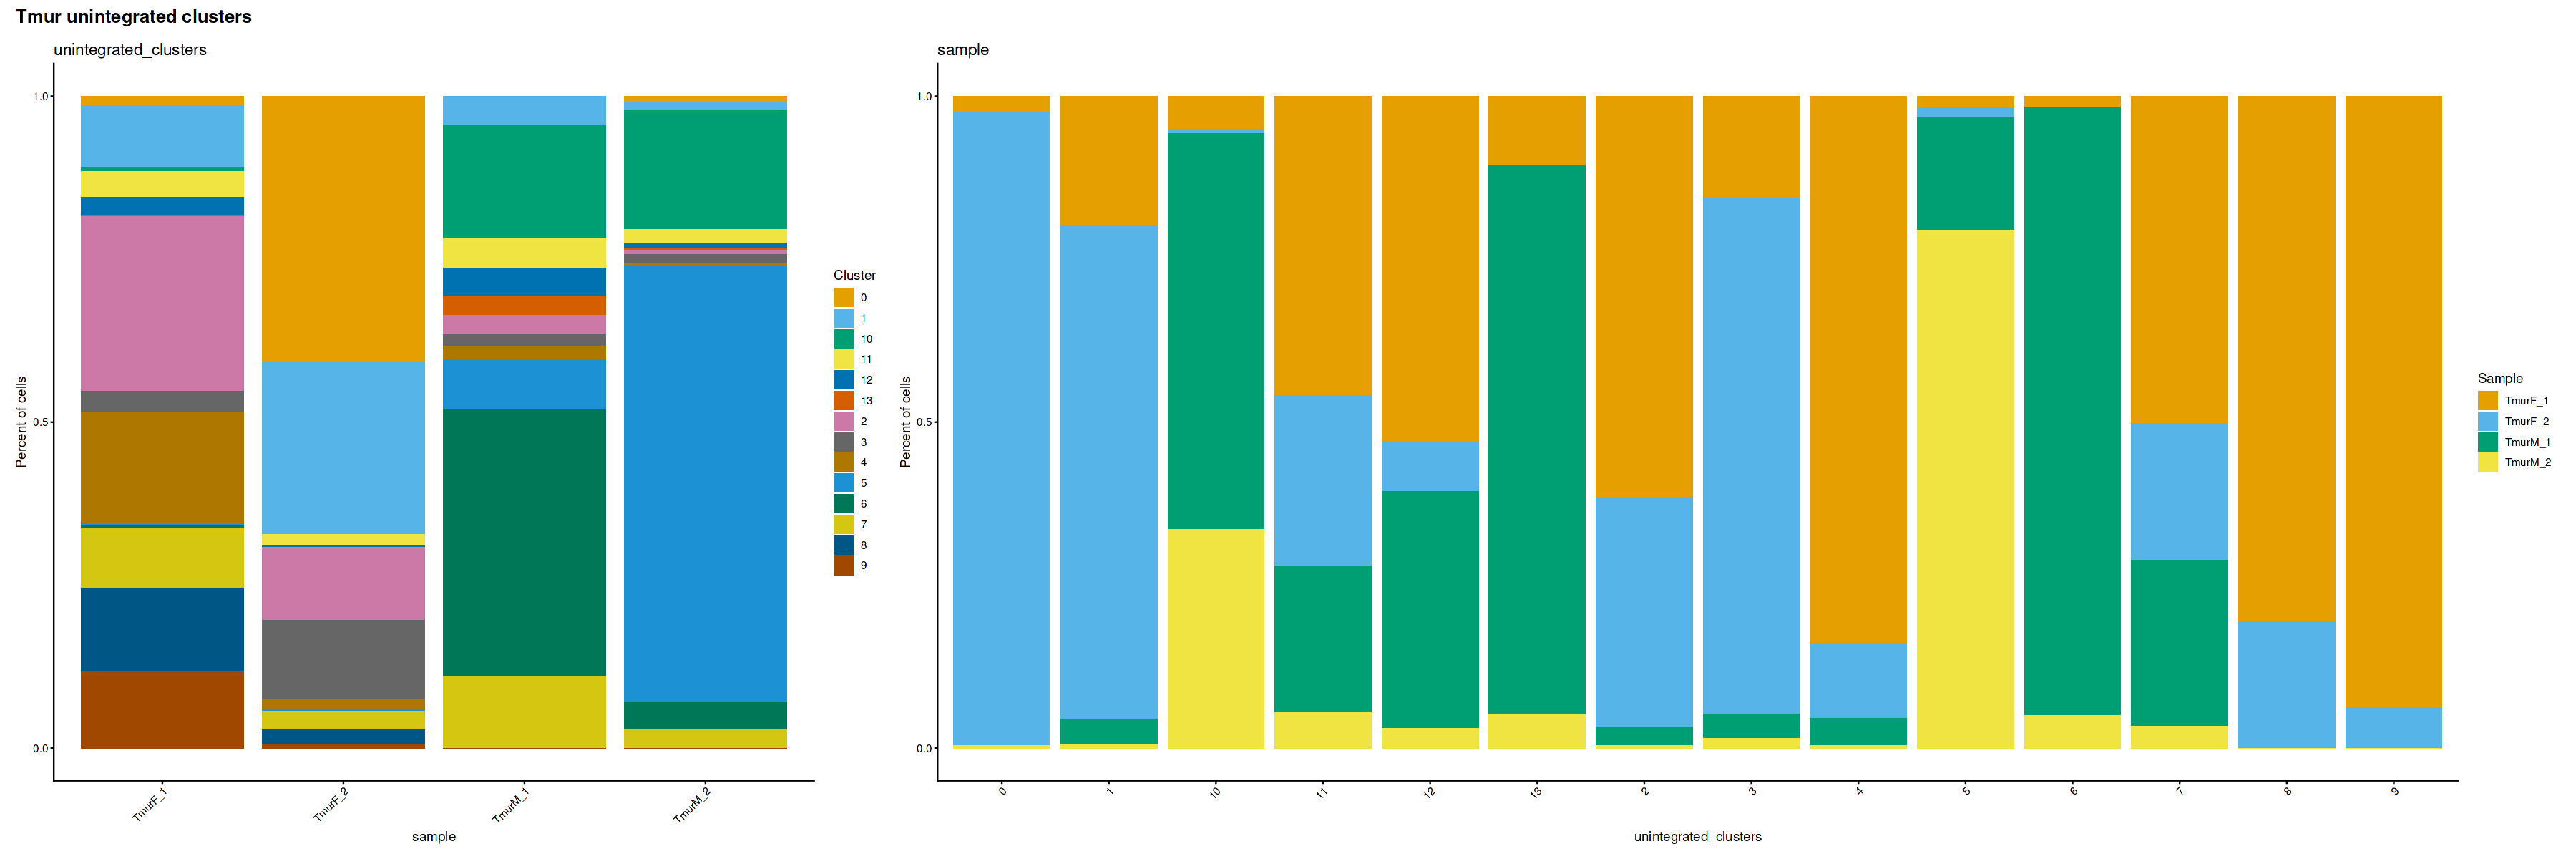

In [13]:
options(repr.plot.width=30, repr.plot.height=10)
p1 <- dittoBarPlot(Tmur_obj, var = "unintegrated_clusters", group.by = "sample", scale = "percent", legend.title = "Cluster") + plot_annotation(title = 'Tmur unintegrated clusters', theme = theme(plot.title = element_text(size = 15, face = "bold")))
p2 <- dittoBarPlot(Tmur_obj, var = "sample", group.by = "unintegrated_clusters", scale = "percent", legend.title = "Sample")
p1 + p2 + plot_layout(widths = c(10, 20))
ggsave(file = "Tmur_unintegrated_cluster_percent.png", width = 15, height = 5, dpi = 600, units = "in")

In [ ]:
# Harmony integration
Hcon_obj <- IntegrateLayers(Hcon_obj, method = HarmonyIntegration, orig.reduction = "pca", new.reduction = "integrated.harmony", verbose = FALSE)
Tmur_obj <- IntegrateLayers(Tmur_obj, method = HarmonyIntegration, orig.reduction = "pca", new.reduction = "integrated.harmony", verbose = FALSE)

In [ ]:
Hcon_obj <- FindNeighbors(Hcon_obj, reduction = "integrated.harmony",  dims = 1:30) %>% 
  FindClusters(resolution = 0.8, cluster.name = "harmony_clusters") %>%
  RunUMAP(dims=1:30, reduction = "integrated.harmony", reduction.name = "umap.harmony")

Tmur_obj <- FindNeighbors(Tmur_obj, reduction = "integrated.harmony",  dims = 1:30) %>% 
  FindClusters(resolution = 0.8, cluster.name = "harmony_clusters") %>%
  RunUMAP(dims=1:30, reduction = "integrated.harmony", reduction.name = "umap.harmony")

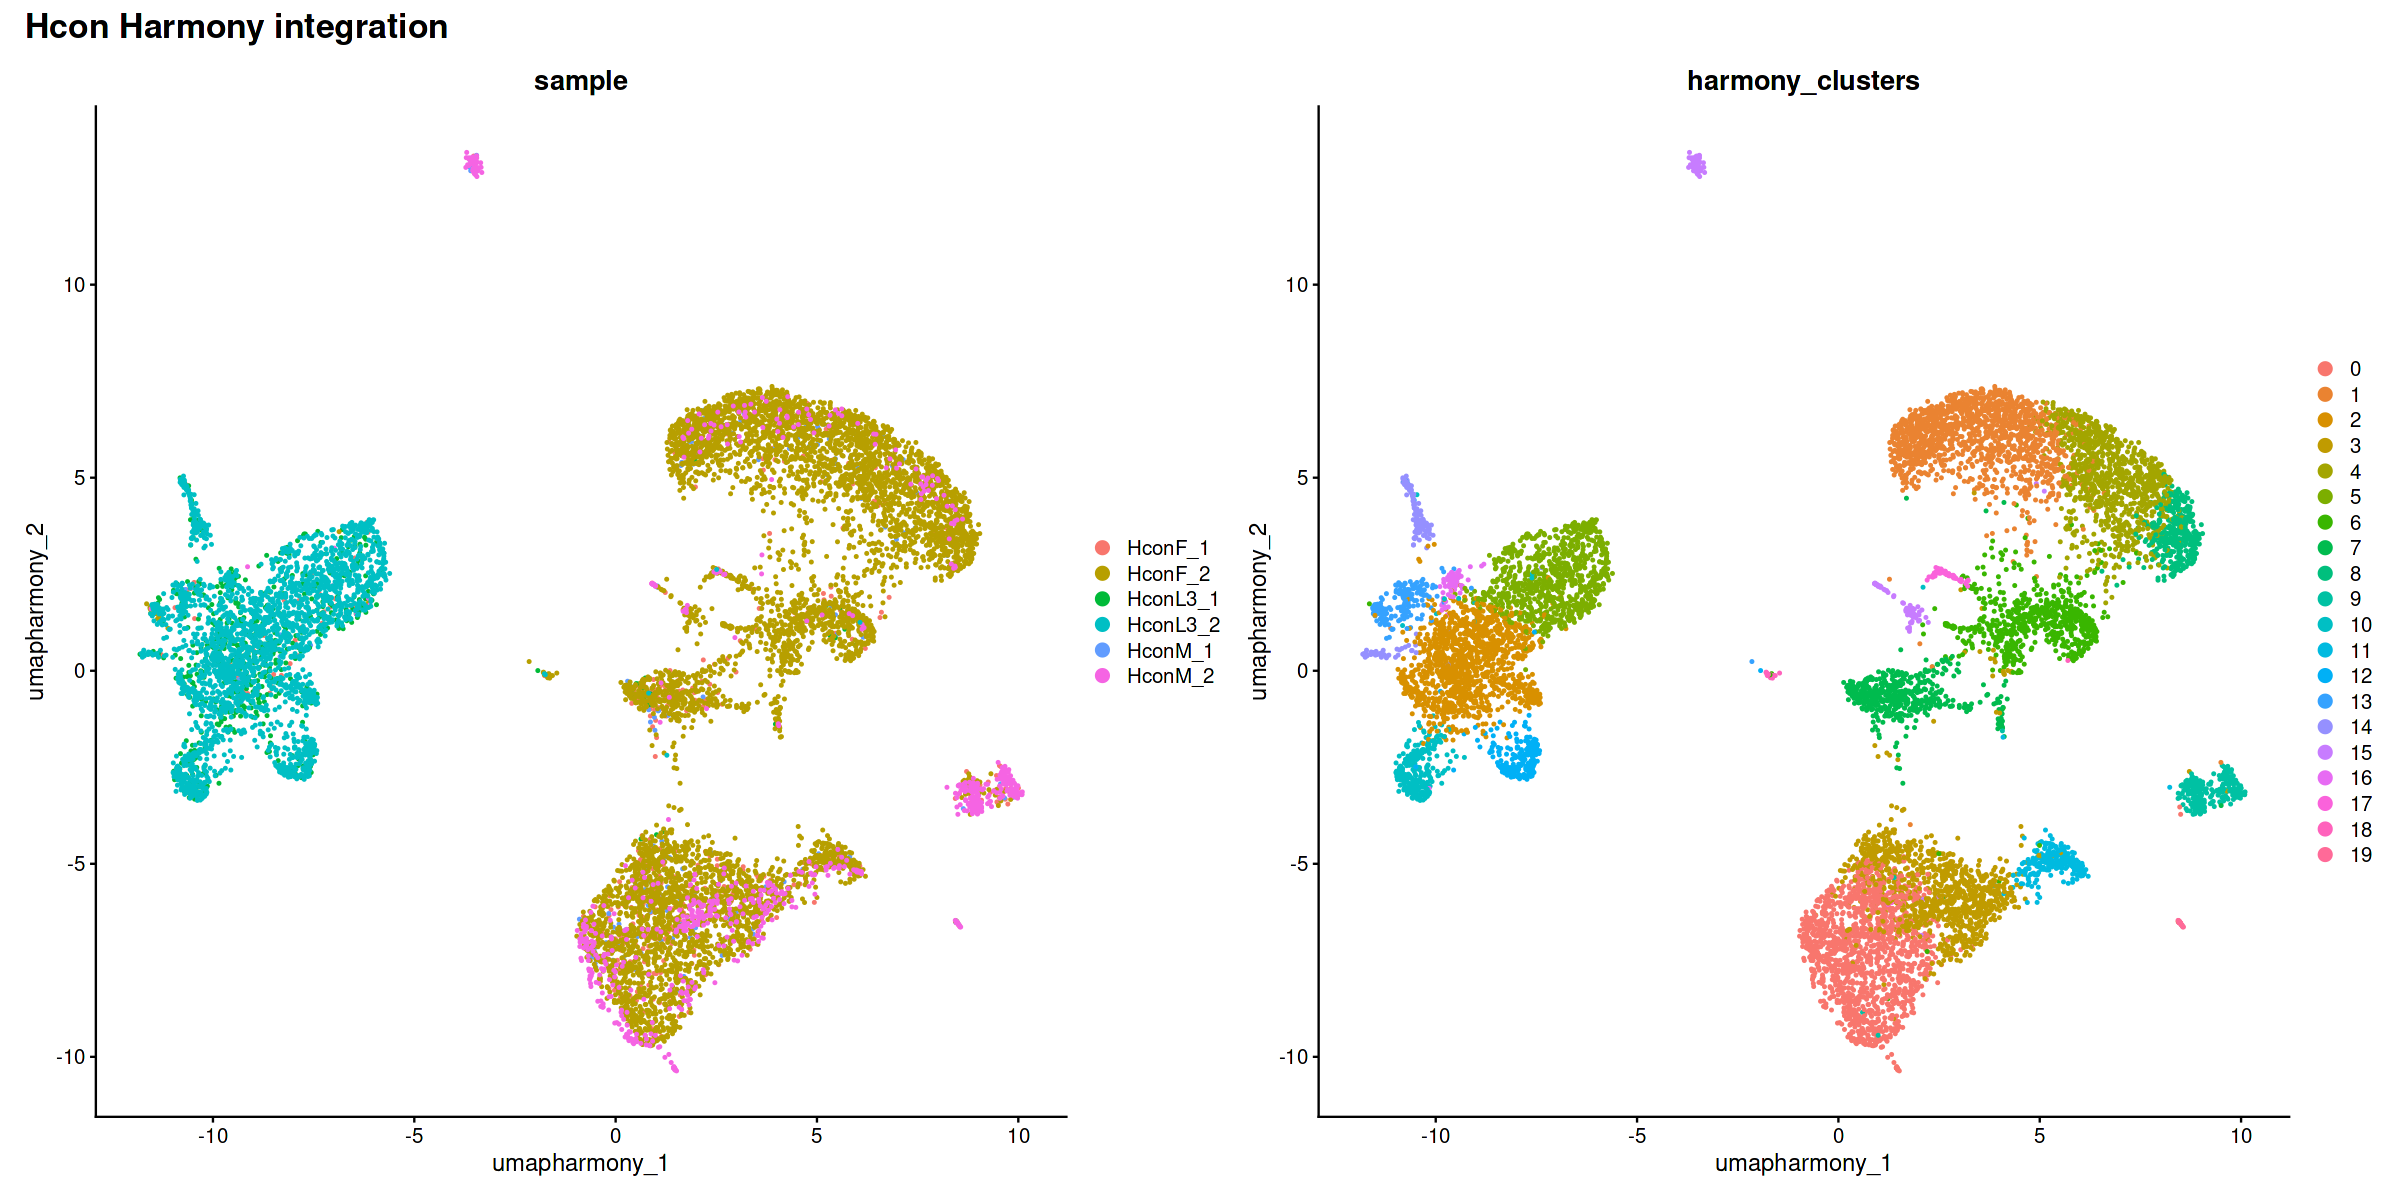

In [18]:
options(repr.plot.width=20, repr.plot.height=10)
DimPlot(Hcon_obj, reduction = "umap.harmony", raster = FALSE, group.by = c("sample", "harmony_clusters")) + plot_annotation(title = 'Hcon Harmony integration', theme = theme(plot.title = element_text(size = 20, face = "bold")))
ggsave(file = "../05_figures/Hcon_harmony_UMAP.png", width = 10, height = 5, dpi = 600, units = "in")

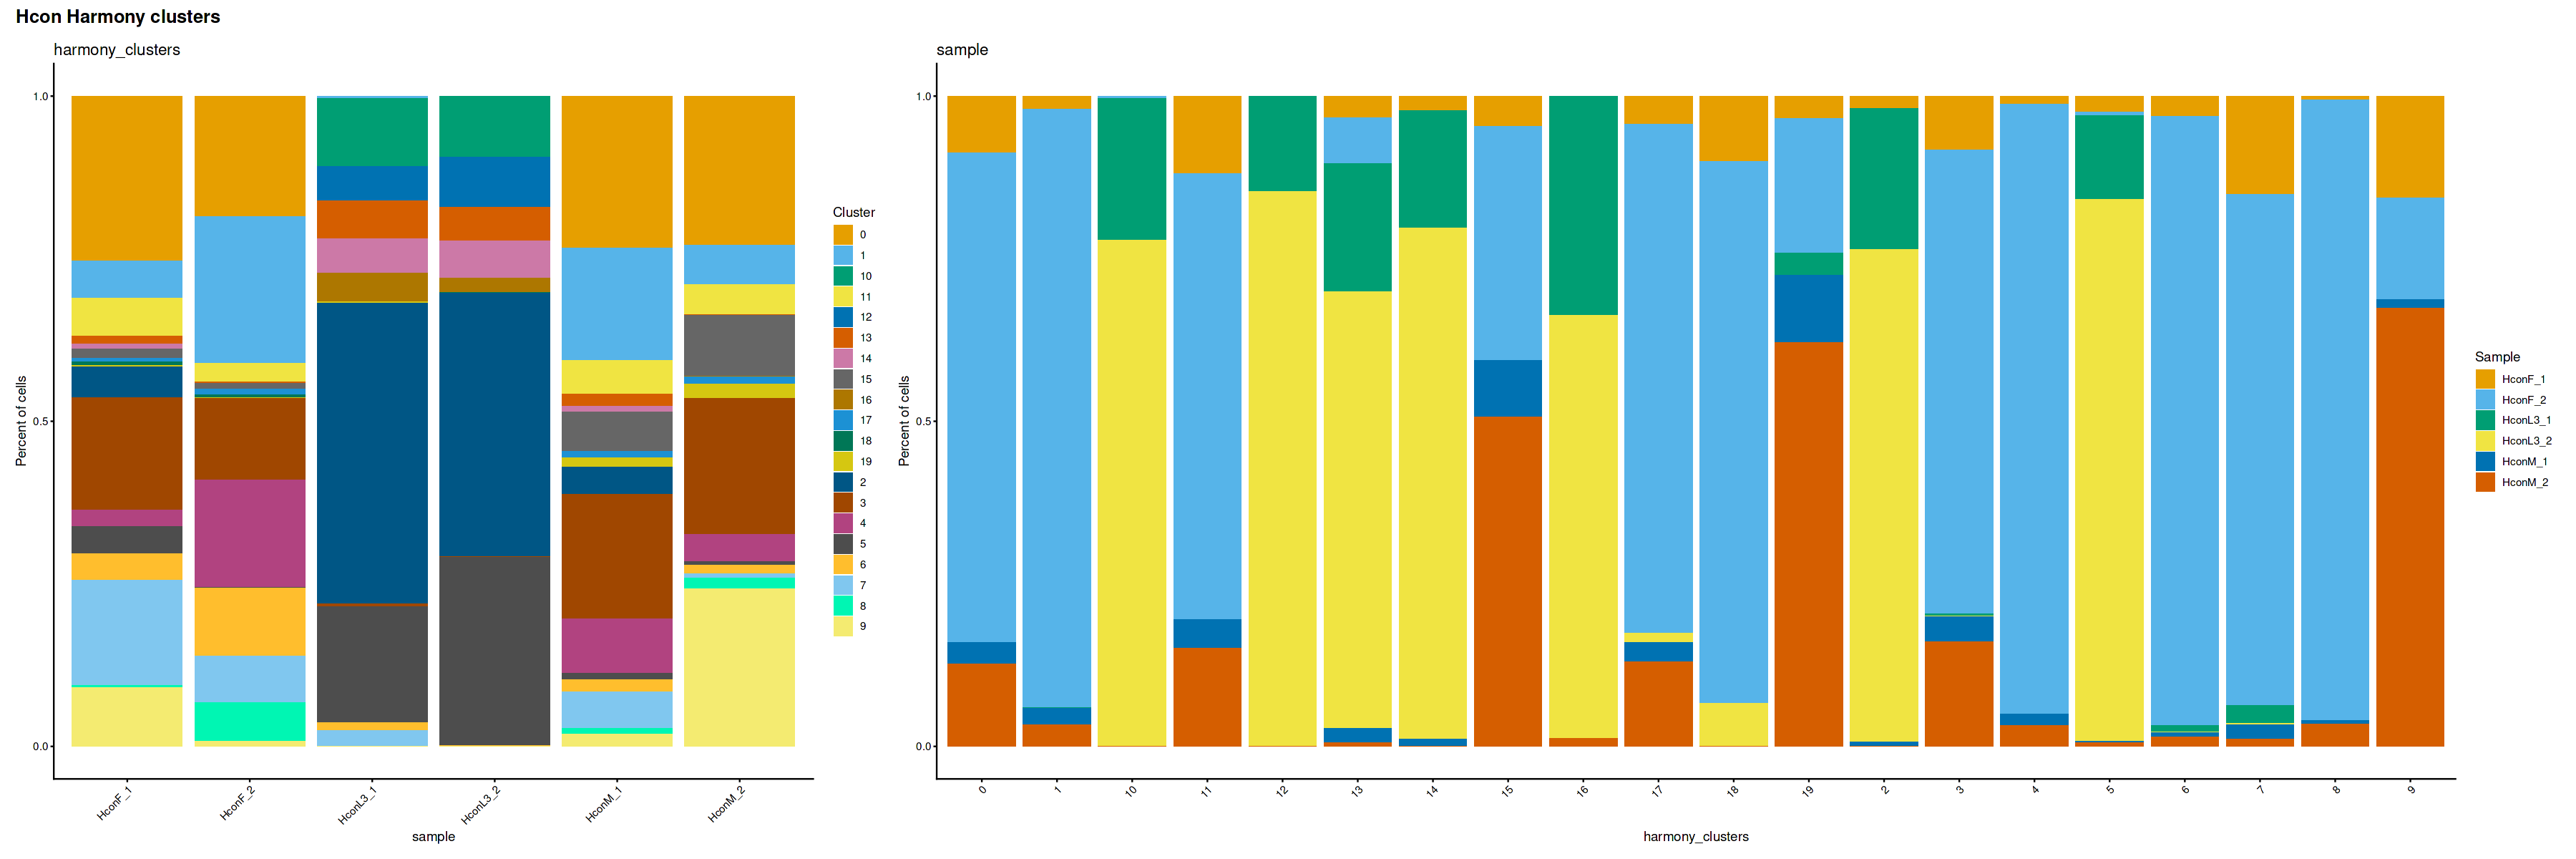

In [19]:
options(repr.plot.width=30, repr.plot.height=10)
p1 <- dittoBarPlot(object = Hcon_obj, var = "harmony_clusters", group.by = "sample", scale = "percent", legend.title = "Cluster") + plot_annotation(title = 'Hcon Harmony clusters', theme = theme(plot.title = element_text(size = 15, face = "bold")))
p2 <- dittoBarPlot(object = Hcon_obj, var = "sample", group.by = "harmony_clusters", scale = "percent", legend.title = "Sample")
p1 + p2 + plot_layout(widths = c(10, 20))
ggsave(file = "../05_figures/Hcon_harmony_percent.png", width = 15, height = 5, dpi = 600, units = "in")

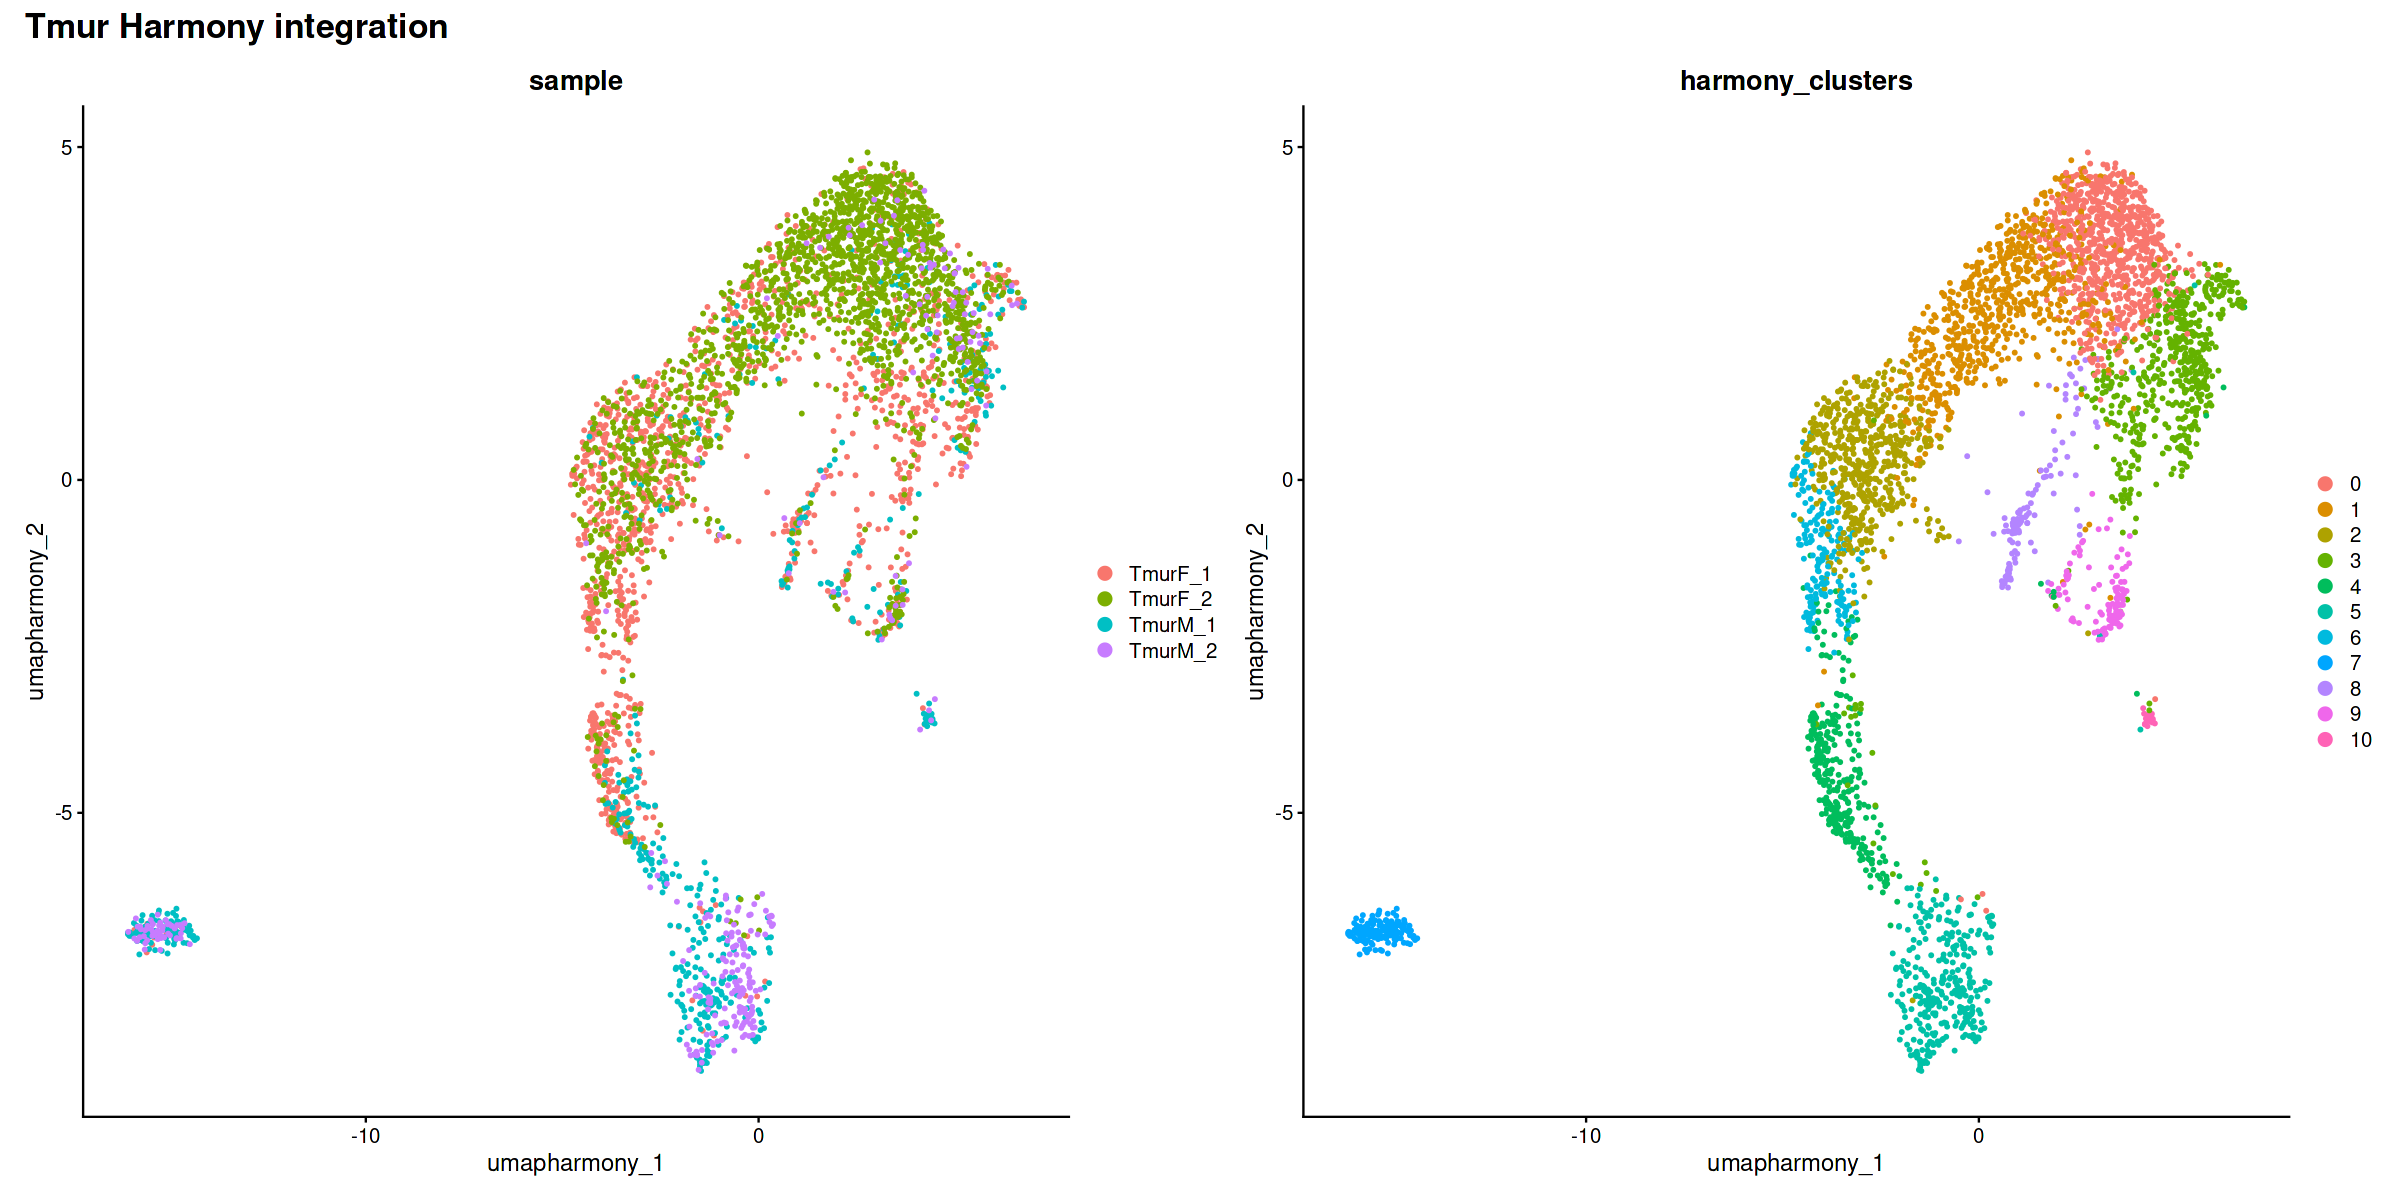

In [15]:
options(repr.plot.width=20, repr.plot.height=10)
DimPlot(Tmur_obj, reduction = "umap.harmony", raster = FALSE, group.by = c("sample", "harmony_clusters")) + plot_annotation(title = 'Tmur Harmony integration', theme = theme(plot.title = element_text(size = 20, face = "bold")))
ggsave(file = "../05_figures/Tmur_harmony_UMAP.png", width = 20, height = 10, dpi = 600, units = "in")

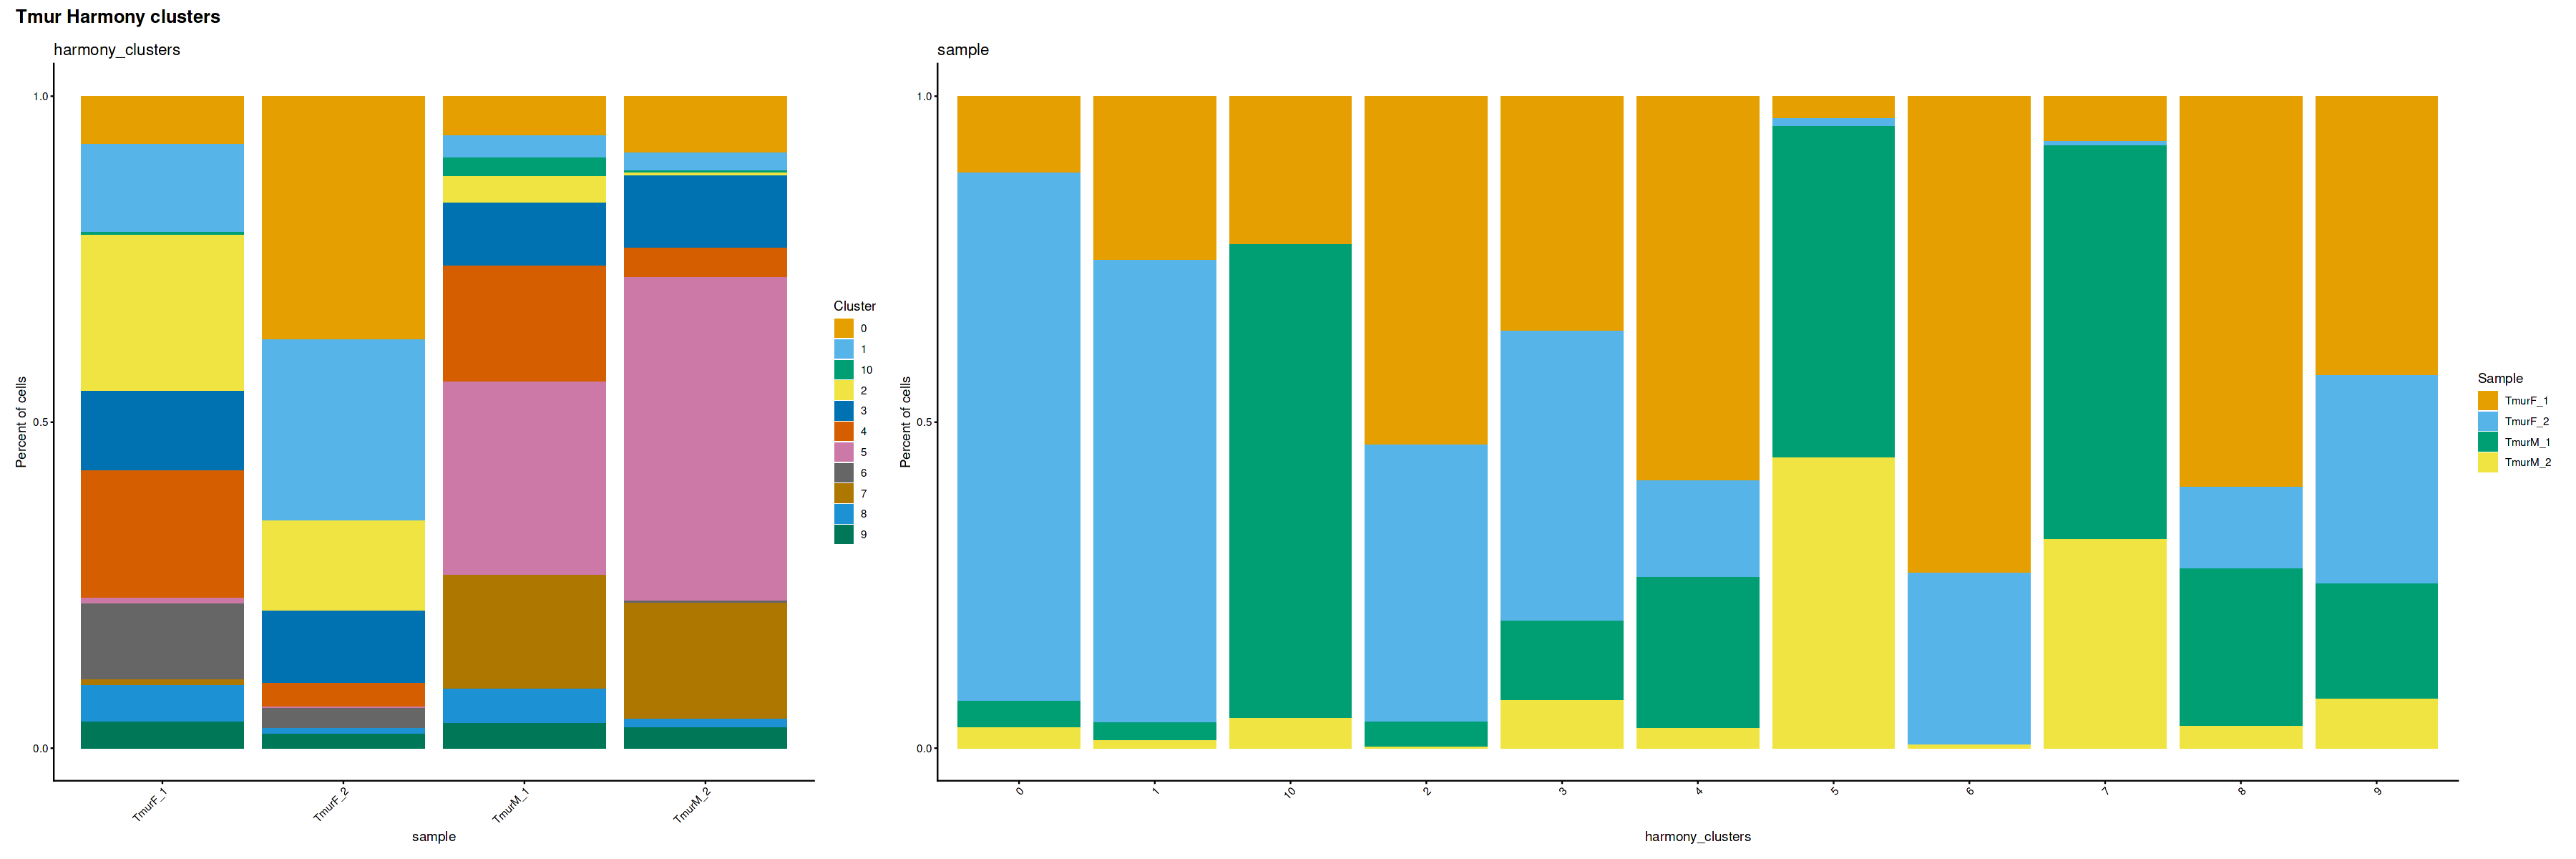

In [20]:
options(repr.plot.width=30, repr.plot.height=10)
p1 <- dittoBarPlot(object = Tmur_obj, var = "harmony_clusters", group.by = "sample", scale = "percent", legend.title = "Cluster") + plot_annotation(title = 'Tmur Harmony clusters', theme = theme(plot.title = element_text(size = 15, face = "bold")))
p2 <- dittoBarPlot(object = Tmur_obj, var = "sample", group.by = "harmony_clusters", scale = "percent", legend.title = "Sample")
p1 + p2 + plot_layout(widths = c(10, 20))
ggsave(file = "../05_figures/Tmur_harmony_percent.png", width = 15, height = 5, dpi = 600, units = "in")

In [22]:
# Save merged Seurat objects
saveRDS(Hcon_obj, "seurat_obj/Hcon_harmony.rds")
saveRDS(Tmur_obj, "seurat_obj/Tmur_harmony.rds")

# Check files were written
writeLines(list.files("seurat_obj", pattern = "_harmony.rds"))

Hcon_harmony.rds
Tmur_harmony.rds


In [23]:
sessionInfo()

R version 4.4.0 (2024-04-24)
Platform: x86_64-pc-linux-gnu
Running under: Ubuntu 22.04.5 LTS

Matrix products: default
BLAS:   /software/isg/languages/R/4.4.0/exec/lib/R/lib/libRblas.so 
LAPACK: /software/isg/languages/R/4.4.0/exec/lib/R/lib/libRlapack.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=en_GB.utf8       LC_NUMERIC=C             
 [3] LC_TIME=en_GB.utf8        LC_COLLATE=en_GB.utf8    
 [5] LC_MONETARY=en_GB.utf8    LC_MESSAGES=en_GB.utf8   
 [7] LC_PAPER=en_GB.utf8       LC_NAME=C                
 [9] LC_ADDRESS=C              LC_TELEPHONE=C           
[11] LC_MEASUREMENT=en_GB.utf8 LC_IDENTIFICATION=C      

time zone: Europe/London
tzcode source: system (glibc)

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
[1] patchwork_1.3.2      future_1.70.0        dittoSeq_1.18.0     
[4] ggplot2_4.0.3        dplyr_1.1.4          SeuratWrappers_0.3.2
[7] Seurat_5.0.0         SeuratObject_5.2.0   sp_2.2-1

In [24]:
# Remove all hidden and visible objects stored in R workspace
rm(list = ls(all.names = TRUE))
quit(save = "no")